# 04 · Validación de etiquetas, reportes de calidad y corpus de Schema Linking

Objetivos:

1. Auditar integridad, consistencia de esquema, consistencia de etiquetas y particiones (`src/dataset_validator.py`).
2. Analizar la distribución de clases (relevancia y roles) y las construcciones SQL (`src/statistics.py`).
3. Analizar los errores y los casos pendientes de revisión manual.
4. Construir los corpus JSONL de relevancia y roles por partición (`src/dataset_builder.py`), sin Catastro en el entrenamiento.


In [1]:
# Configuración común: localizar la raíz del proyecto y habilitar `src/`
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

from src import config
config.ensure_directories()
print("Raíz del proyecto:", ROOT.name)

Raíz del proyecto: proyecto_jarm


In [2]:
from src.data_loader import load_master_dataset
from src.schema_parser import load_schema_catalog, schema_summary
from src.sql_parser import load_sql_analysis
from src.schema_annotator import load_annotations, load_all_annotations

master = load_master_dataset()
catalog = load_schema_catalog()
analysis = load_sql_analysis()
annotations = {s: load_annotations(s) for s in config.SOURCES}
all_ann = pd.concat(annotations.values(), ignore_index=True)
print({s: len(a) for s, a in annotations.items()})

{'SPIDER': 299736, 'BIRD': 963578, 'CATASTRO': 164240}


## 1. Auditoría automática

Ningún control elimina registros: los problemas se documentan en `outputs/quality_reports/`.

In [3]:
from src.dataset_validator import run_all_validations

report = run_all_validations(master, catalog, analysis, annotations, save=True)
summary = report.summary_frame()
print("Controles ejecutados:", len(summary), "| con errores:", (summary.severity == "error").sum(), "| advertencias:", (summary.severity == "warning").sum())
summary[summary.severity.isin(["error", "warning"])].reset_index(drop=True)

2026-11-06 22:51:04,415 | INFO | src.dataset_validator | Validación: 120 controles, 0 con errores, 14 advertencias
2026-11-06 22:51:04,433 | INFO | src.dataset_validator | Reportes de calidad guardados: ['outputs/quality_reports/validation_summary.csv', 'outputs/quality_reports/duplicates.csv', 'outputs/quality_reports/unresolved_references.csv', 'outputs/quality_reports/questions_manual_review.csv', 'outputs/quality_reports/partition_distribution.csv']
Controles ejecutados: 120 | con errores: 0 | advertencias: 14


,category,check,source,count,severity,note
0,integridad,registros_duplicados_pregunta_sql,BIRD,12,warning,"marcados, no eliminados"
1,integridad,registros_duplicados_pregunta_sql,SPIDER,18,warning,"marcados, no eliminados"
2,parser,consultas_parcialmente_resueltas,BIRD,315,warning,NaN
3,parser,consultas_sin_resolver,BIRD,34,warning,NaN
4,esquema,tablas_usadas_inexistentes,BIRD,199,warning,NaN
5,esquema,columnas_usadas_inexistentes,BIRD,531,warning,NaN
6,esquema,alias_sin_resolver,BIRD,425,warning,NaN
7,esquema,alias_duplicados_en_sql,BIRD,1,warning,NaN
8,parser,consultas_parcialmente_resueltas,SPIDER,1,warning,NaN
9,esquema,tablas_usadas_inexistentes,SPIDER,1,warning,NaN


In [4]:
print("Controles de consistencia de etiquetas (todos deben ser 0 salvo los informativos):")
summary[summary.category == "etiquetas"].pivot_table(index="check", columns="source", values="count", aggfunc="sum", fill_value=0)

Controles de consistencia de etiquetas (todos deben ser 0 salvo los informativos):


source,BIRD,CATASTRO,SPIDER
check,,,
anotaciones_automatic,941694,164240,299658
anotaciones_manual_review,21884,0,78
elementos_duplicados_por_pregunta,0,0,0
elementos_usados_con_relevancia_0,0,0,0
irrelevantes_con_roles,0,0,0
preguntas_con_candidatos_incompletos,0,0,0
preguntas_pendientes_revision_manual,349,0,1
relevantes_sin_roles,0,0,0
roles_inconsistentes_con_clausulas_sql,0,0,0


## 2. Distribución de clases

In [4]:
from src import statistics as stats
from IPython.display import Image, display

tables = stats.run_all_statistics(master, schema_summary(catalog), analysis, all_ann, save=True)
print("Relevancia por fuente/partición/tipo de elemento (% de candidatos relevantes):")
rel = tables["relevance"]
rel[rel.relevance == 1].pivot_table(index=["source", "split"], columns="element_type", values="pct")

2026-11-06 22:51:32,803 | INFO | src.statistics | Estadísticas generadas en D:\backup\MAESTRIA\MINE\2026_2\ProcesamientoLenguajeNatural\Tareas\proyecto_jarm\outputs\statistics
Relevancia por fuente/partición/tipo de elemento (% de candidatos relevantes):


element_type            column  table
source   split                       
BIRD     test             9.39  24.30
         train            5.49  16.08
         validation       5.95  27.43
CATASTRO test_transfer    0.44   1.42
SPIDER   train            8.97  25.74
         validation      11.10  33.46

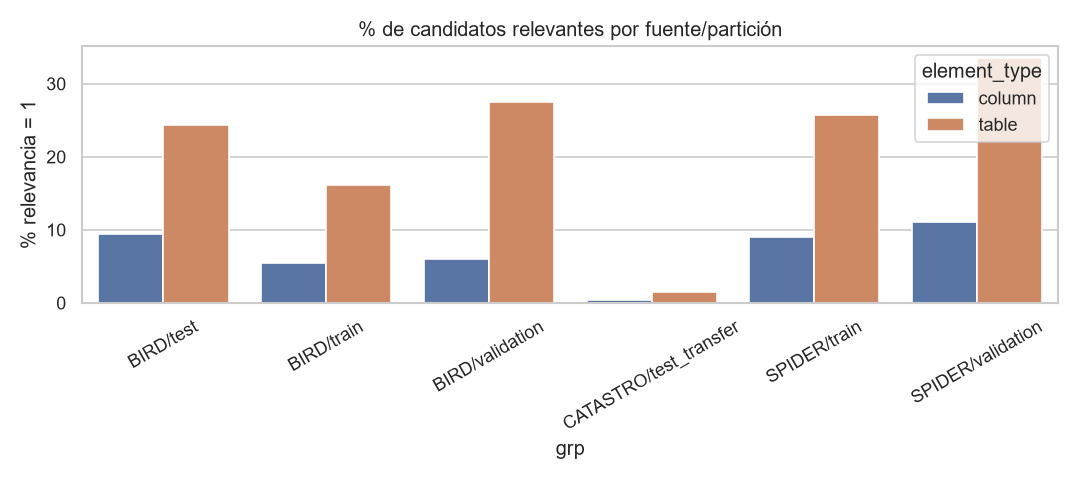

Candidatos por pregunta:


,source,n_questions,tables_mean,columns_mean,total_mean,total_median,total_min,total_max
0,BIRD,10962,11.11,76.79,87.90,60.0,9,520
1,CATASTRO,80,232.00,1821.00,2053.00,2053.0,2053,2053
2,SPIDER,8034,5.84,31.47,37.31,27.0,9,378


In [6]:
display(Image(filename=str(config.STATISTICS_DIR / "06_relevance_distribution.png")))
print("Candidatos por pregunta:"); display(tables["candidates"])

Distribución de los 7 roles entre elementos relevantes:


element_type column                   table                 
source         BIRD CATASTRO SPIDER    BIRD CATASTRO  SPIDER
role                                                        
SELECT        29.69    51.62  44.81    0.00     0.00    0.00
WHERE         30.10    26.12  20.99    0.00     0.00    0.00
JOIN          43.13    56.57  34.42   87.25    96.21   57.91
FROM           0.00     0.00   0.00  100.00   100.00  100.00
GROUP_BY       2.68     2.94   8.96    0.00     0.00    0.00
HAVING         0.25     0.77   0.16    0.00     0.00    0.00
ORDER_BY       4.07     0.15   3.91    0.00     0.00    0.00

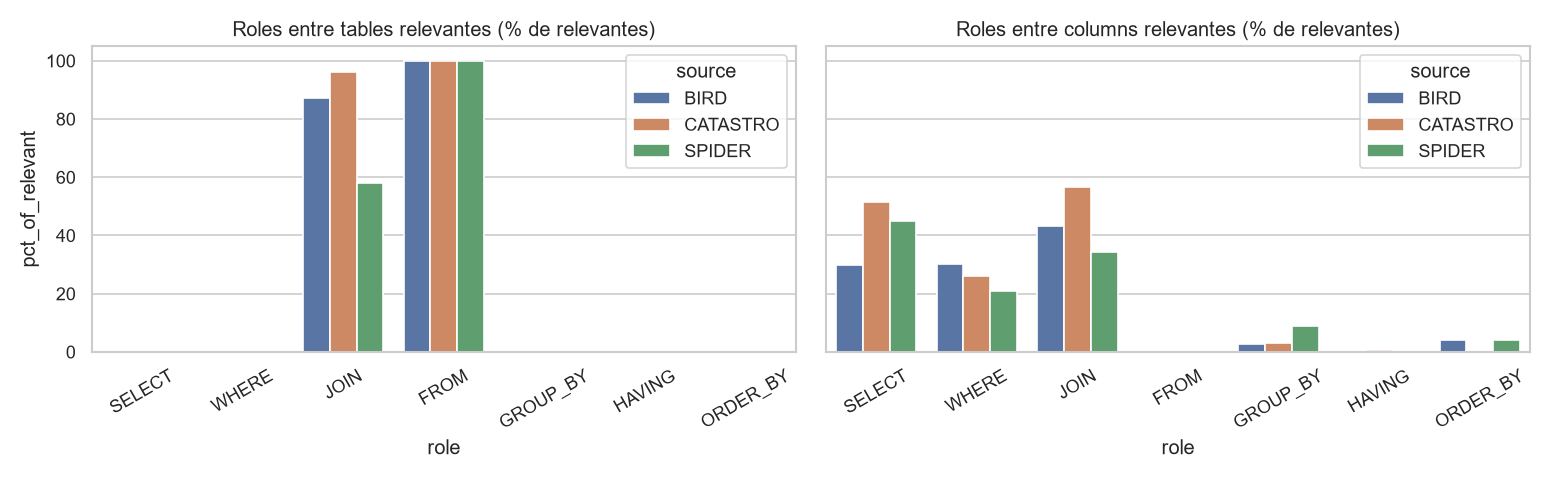

In [5]:
print("Distribución de los 7 roles entre elementos relevantes:")
display(tables["roles"].pivot_table(index="role", columns=["element_type", "source"], values="pct_of_relevant").reindex(config.ROLE_LABELS))
display(Image(filename=str(config.STATISTICS_DIR / "07_roles_distribution.png")))

In [6]:
print("Número de roles simultáneos por elemento relevante:")
pd.read_csv(config.STATISTICS_DIR / "07_roles_per_element_count.csv").pivot(index="n_roles", columns="source", values="n").fillna(0).astype(int)

Número de roles simultáneos por elemento relevante:


source,BIRD,CATASTRO,SPIDER
n_roles,,,
1,47855,438,25736
2,23012,448,9571
3,395,22,353
4,34,3,2
5,1,0,0


Construcciones SQL (% de consultas):


source,BIRD,CATASTRO,SPIDER
has_join,76.19,88.75,39.57
has_subquery,7.67,1.25,7.27
has_cte,0.08,12.50,0.00
has_where,88.12,97.50,49.73
has_group_by,10.30,11.25,25.54
has_having,1.46,7.50,6.30
has_order_by,18.49,1.25,23.21
has_limit,19.13,0.00,16.13
has_distinct,12.07,1.25,10.06
has_aggregation,46.95,11.25,47.56


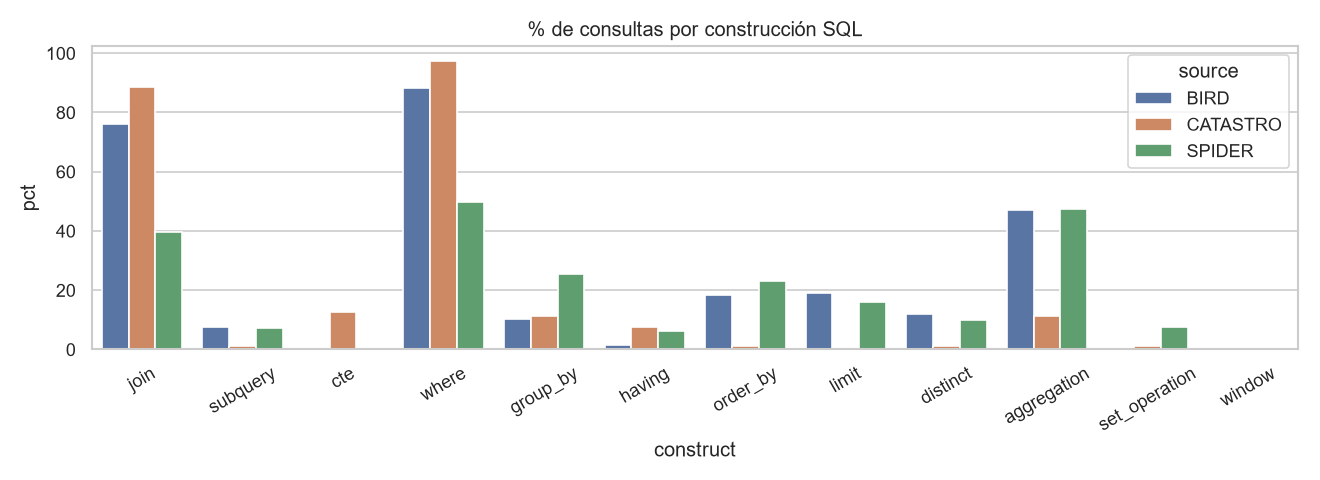

In [7]:
print("Construcciones SQL (% de consultas):"); display(pd.read_csv(config.STATISTICS_DIR / "08_sql_constructs_pct.csv").set_index("source").T)
display(Image(filename=str(config.STATISTICS_DIR / "08_sql_constructs.png")))

## 3. Verificación de etiquetas (muestreo)

Se recalculan manualmente, para una muestra aleatoria, los elementos usados por el parser y se comparan con las anotaciones.

In [8]:
sample = analysis[(analysis.source != "CATASTRO") & (analysis.resolution_status == "resolved")].sample(300, random_state=config.RANDOM_SEED)
ann_idx = all_ann.set_index(["example_id", "element_id"])
mismatch = 0
for r in sample.itertuples():
    d = json.loads(r.analysis_json)
    for eid, roles in list(d["table_roles"].items()) + list(d["column_roles"].items()):
        row = ann_idx.loc[(r.example_id, eid)]
        expected = [1 if lab in roles else 0 for lab in config.ROLE_LABELS]
        if row.relevance != 1 or list(row.roles) != expected:
            mismatch += 1
print(f"Elementos verificados en 300 preguntas: discrepancias = {mismatch}")

Elementos verificados en 300 preguntas: discrepancias = 0


In [9]:
# Revisión cualitativa: preguntas aleatorias con sus elementos relevantes y roles
from src.schema_annotator import example_annotation_view
for eid in master[master.source != "CATASTRO"].sample(2, random_state=7).example_id:
    m = master.set_index("example_id").loc[eid]
    print("\n", eid, "|", m.question, "\n", m.sql_gold)
    display(example_annotation_view(annotations[m.source], eid))


 BIRD-train-06378 | Among the beverages, which product has the highest customer satisfaction? 
 SELECT T1.ProductName FROM Products AS T1 INNER JOIN Categories AS T2 ON T1.CategoryID = T2.CategoryID WHERE T2.CategoryName = 'Beverages' ORDER BY T1.ReorderLevel DESC LIMIT 1


,element_id,element_type,relevance,role_SELECT,role_WHERE,role_JOIN,role_FROM,role_GROUP_BY,role_HAVING,role_ORDER_BY,annotation_status,annotation_notes
0,Categories,table,1,0,0,1,1,0,0,0,manual_review,unresolved_references=column:T1.ReorderLevel:column_not_in_table:Products
1,Products,table,1,0,0,1,1,0,0,0,manual_review,unresolved_references=column:T1.ReorderLevel:column_not_in_table:Products
2,Categories.CategoryID,column,1,0,0,1,0,0,0,0,manual_review,unresolved_references=column:T1.ReorderLevel:column_not_in_table:Products
3,Categories.CategoryName,column,1,0,1,0,0,0,0,0,manual_review,unresolved_references=column:T1.ReorderLevel:column_not_in_table:Products
4,Products.ProductName,column,1,1,0,0,0,0,0,0,manual_review,unresolved_references=column:T1.ReorderLevel:column_not_in_table:Products
5,Products.CategoryID,column,1,0,0,1,0,0,0,0,manual_review,unresolved_references=column:T1.ReorderLevel:column_not_in_table:Products



 SPIDER-train-05199 | What is the last name of the musicians who has played back position the most? 
 SELECT T2.lastname FROM Performance AS T1 JOIN Band AS T2 ON T1.bandmate  =  T2.id WHERE stageposition  =  "back" GROUP BY lastname ORDER BY count(*) DESC LIMIT 1


,element_id,element_type,relevance,role_SELECT,role_WHERE,role_JOIN,role_FROM,role_GROUP_BY,role_HAVING,role_ORDER_BY,annotation_status,annotation_notes
0,Band,table,1,0,0,1,1,0,0,0,automatic,star_projection
1,Performance,table,1,0,0,1,1,0,0,0,automatic,star_projection
2,Band.Id,column,1,0,0,1,0,0,0,0,automatic,NaN
3,Band.Lastname,column,1,1,0,0,0,1,0,0,automatic,NaN
4,Performance.Bandmate,column,1,0,0,1,0,0,0,0,automatic,NaN
5,Performance.StagePosition,column,1,0,1,0,0,0,0,0,automatic,NaN


## 4. Análisis de errores y casos pendientes

In [10]:
unres = pd.read_csv(config.QUALITY_DIR / "unresolved_references.csv")
print("Referencias no resueltas:", len(unres))
display(unres.groupby(["source", "kind", unres.reason.str.split(":").str[0]]).size().rename("n").reset_index())
print("Por base de datos:"); display(unres.groupby(["source", "db_id"]).agg(n_refs=("example_id", "size"), n_questions=("example_id", "nunique")).sort_values("n_refs", ascending=False))

Referencias no resueltas: 1159


,source,kind,reason,n
0,BIRD,column,alias_not_found,425
1,BIRD,column,column_not_found,214
2,BIRD,column,column_not_in_table,317
3,BIRD,scope,duplicate_alias,1
4,BIRD,table,table_not_in_schema,199
5,SPIDER,column,alias_not_found,1
6,SPIDER,column,column_not_in_table,1
7,SPIDER,table,table_not_in_schema,1


Por base de datos:


n_refs  n_questions
source db_id                                  
BIRD   retail_world          1116          330
       works_cycles            27           10
       app_store                7            4
       shooting                 4            4
SPIDER assets_maintenance       3            1
BIRD   social_media             2            1

In [13]:
mr = pd.read_csv(config.QUALITY_DIR / "questions_manual_review.csv")
print("Preguntas pendientes de revisión manual:", len(mr))
display(mr.groupby(["source", "split"]).size().rename("n_questions"))
mr[["example_id", "db_id", "question", "annotation_notes"]].head(5)

Preguntas pendientes de revisión manual: 350


source  split
BIRD    test       4
        train    345
SPIDER  train      1
Name: n_questions, dtype: int64

,example_id,db_id,question,annotation_notes
0,SPIDER-train-03153,assets_maintenance,What is the description of the type of the company who concluded its contracts most recently?,unresolved_references=column:T1.company_type_code:column_not_in_table:Third_Party_Companies; column:T3.company_type_...
1,BIRD-train-00793,social_media,Please list the texts of all the tweets posted by male users from Buenos Aires.,unresolved_references=column:T2.UserID:column_not_in_table:location; scope:SELECT T1.text FROM twitter AS T1 INNER J...
2,BIRD-train-02462,shooting,What is the percentage of the cases involved more than 3 officers from year 2010 to 2015?,unresolved_references=column:officer_count:column_not_found
3,BIRD-train-02464,shooting,"Among the cases dismissed by the grand jury disposition, what percentage of cases is where the subject is injured?",unresolved_references=column:grand_jury_disposition:column_not_found
4,BIRD-train-02467,shooting,Who are the officers involved in cases that are voted as 'No Bill'. List their last name and gender.,unresolved_references=column:T1.grand_jury_disposition:column_not_in_table:incidents


In [14]:
print("Elementos más frecuentes en referencias no resueltas (columnas inexistentes en la metadata de BIRD):")
unres[unres.kind == "column"].assign(col=lambda d: d.raw.str.split(".").str[-1]).groupby(["db_id", "col"]).size().sort_values(ascending=False).head(12)

Elementos más frecuentes en referencias no resueltas (columnas inexistentes en la metadata de BIRD):


db_id         col                 
retail_world  CompanyName             126
              TerritoryID              75
              UnitPrice                68
              RegionID                 65
              ProductID                57
              OrderID                  55
              Quantity                 48
              EmployeeID               39
              Title                    37
              ShipVia                  32
              Salary                   32
              TerritoryDescription     28
dtype: int64

**Conclusión del análisis de errores.** Los 350 casos pendientes (349 BIRD, 1 Spider) no son fallos del parser sino inconsistencias entre
el SQL gold y la metadata de esquema distribuida con los benchmarks (`retail_world` concentra 330). Se mantienen en los Parquet de anotaciones
con estado `manual_review` y se excluyen por defecto de los corpus de entrenamiento. Opciones para la siguiente etapa: (a) completar la metadata
de `retail_world` desde la base `.sqlite` original si se obtiene, o (b) mantener la exclusión (~3 % de BIRD).


## 5. Construcción de los corpus de Schema Linking

* `relevance_{train,validation,test}.jsonl`: positivos y negativos (Spider + BIRD).
* `roles_{train,validation,test}.jsonl`: solo elementos relevantes con anotación válida.
* `*_test_transfer.jsonl`: Catastro, exclusivamente para evaluación (archivos separados).
* El SQL gold **no** forma parte de la entrada. El esquema completo se referencia por `schema_id` en `schemas_compact.json`
  (incluirlo en cada línea producía archivos de 5–11 GB); cada registro lleva el contexto local de la tabla del elemento.

In [11]:
from src.dataset_builder import build_schema_linking_datasets, read_jsonl

manifest = build_schema_linking_datasets(master, catalog, annotations)
pd.DataFrame(manifest["files"]).T

2026-11-06 23:01:04,660 | INFO | src.dataset_builder | Esquemas compactos (241) guardados en data/schema_linking/schemas_compact.json
2026-11-06 23:03:36,470 | INFO | src.dataset_builder | relevance_train.jsonl: 1002292 registros (81949 pos / 920343 neg)
2026-11-06 23:03:49,240 | INFO | src.dataset_builder | roles_train.jsonl: 81949 registros
2026-11-06 23:04:14,163 | INFO | src.dataset_builder | relevance_validation.jsonl: 157061 registros (14282 pos / 142779 neg)
2026-11-06 23:04:16,517 | INFO | src.dataset_builder | roles_validation.jsonl: 14282 registros
2026-11-06 23:04:29,204 | INFO | src.dataset_builder | relevance_test.jsonl: 81999 registros (9416 pos / 72583 neg)
2026-11-06 23:04:30,718 | INFO | src.dataset_builder | roles_test.jsonl: 9416 registros
2026-11-06 23:04:54,718 | INFO | src.dataset_builder | relevance_test_transfer.jsonl: 164240 registros (911 pos / 163329 neg)
2026-11-06 23:04:54,899 | INFO | src.dataset_builder | roles_test_transfer.jsonl: 911 registros
2026-11-0

,n_records,n_positive,n_negative,n_questions,n_dbs,sources,role_frequency
relevance_train.jsonl,1002292,81949,920343,14650,195,"[BIRD, SPIDER]",NaN
roles_train.jsonl,81949,NaN,NaN,14650,195,"[BIRD, SPIDER]","{'SELECT': 19405, 'WHERE': 14661, 'JOIN': 42384, 'FROM': 26357, 'GROUP_BY': 2797, 'HAVING': 132, 'ORDER_BY': 2264}"
relevance_validation.jsonl,157061,14282,142779,2568,31,"[BIRD, SPIDER]",NaN
roles_validation.jsonl,14282,NaN,NaN,2568,31,"[BIRD, SPIDER]","{'SELECT': 3507, 'WHERE': 2765, 'JOIN': 7148, 'FROM': 4543, 'GROUP_BY': 416, 'HAVING': 20, 'ORDER_BY': 412}"
relevance_test.jsonl,81999,9416,72583,1428,14,[BIRD],NaN
roles_test.jsonl,9416,NaN,NaN,1428,14,[BIRD],"{'SELECT': 1970, 'WHERE': 2191, 'JOIN': 5156, 'FROM': 2809, 'GROUP_BY': 166, 'HAVING': 8, 'ORDER_BY': 234}"
relevance_test_transfer.jsonl,164240,911,163329,80,1,[CATASTRO],NaN
roles_test_transfer.jsonl,911,NaN,NaN,80,1,[CATASTRO],"{'SELECT': 334, 'WHERE': 169, 'JOIN': 620, 'FROM': 264, 'GROUP_BY': 19, 'HAVING': 5, 'ORDER_BY': 1}"


In [12]:
print("Anotaciones excluidas por estado (manual_review / unresolved):"); display(pd.DataFrame(manifest["excluded"]).T)
print("Ejemplo de registro de relevancia:"); print(json.dumps(read_jsonl(config.SCHEMA_LINKING_DIR / "relevance_validation.jsonl", 1)[0], indent=2, ensure_ascii=False))
print("Ejemplo de registro de roles:"); print(json.dumps(read_jsonl(config.SCHEMA_LINKING_DIR / "roles_validation.jsonl", 1)[0], indent=2, ensure_ascii=False))

Anotaciones excluidas por estado (manual_review / unresolved):


,annotations_excluded_by_status,questions_excluded_by_status
train,21870,346
validation,0,0
test,92,4
test_transfer,0,0


Ejemplo de registro de relevancia:
{
  "task": "schema_relevance",
  "example_id": "SPIDER-dev-00000",
  "source": "SPIDER",
  "db_id": "concert_singer",
  "schema_id": "SPIDER:concert_singer",
  "split": "validation",
  "question": "How many singers do we have?",
  "evidence": null,
  "schema": null,
  "schema_foreign_keys": null,
  "schema_ref": "schema_linking/schemas_compact.json",
  "element": "stadium",
  "element_type": "table",
  "element_context": "stadium(Stadium_ID, Location, Name, Capacity, Highest, Lowest, Average)",
  "annotation_status": "automatic",
  "label": 0
}
Ejemplo de registro de roles:
{
  "task": "schema_roles",
  "example_id": "SPIDER-dev-00000",
  "source": "SPIDER",
  "db_id": "concert_singer",
  "schema_id": "SPIDER:concert_singer",
  "split": "validation",
  "question": "How many singers do we have?",
  "evidence": null,
  "schema": null,
  "schema_foreign_keys": null,
  "schema_ref": "schema_linking/schemas_compact.json",
  "element": "singer",
  "element

In [13]:
from src.dataset_validator import ValidationReport, validate_schema_linking_files
rep = ValidationReport(); validate_schema_linking_files(rep)
chk = rep.summary_frame(); print("Registros de Catastro en corpus de entrenamiento/validación/prueba:", int(chk["count"].sum()))
chk

Registros de Catastro en corpus de entrenamiento/validación/prueba: 0


,category,check,source,count,severity,note
0,particiones,catastro_en_relevance_train,SCHEMA_LINKING,0,ok,total_lineas=1002292
1,particiones,catastro_en_relevance_validation,SCHEMA_LINKING,0,ok,total_lineas=157061
2,particiones,catastro_en_relevance_test,SCHEMA_LINKING,0,ok,total_lineas=81999
3,particiones,catastro_en_roles_train,SCHEMA_LINKING,0,ok,total_lineas=81949
4,particiones,catastro_en_roles_validation,SCHEMA_LINKING,0,ok,total_lineas=14282
5,particiones,catastro_en_roles_test,SCHEMA_LINKING,0,ok,total_lineas=9416


## 6. Estructura del corpus Text-to-SQL (siguiente entrega)

Se deja definido el formato del generador y se escribe una muestra construida con el esquema enfocado derivado de las anotaciones gold (sin usar el SQL gold como entrada).

In [14]:
from src.dataset_builder import write_generator_format_sample
write_generator_format_sample(master, catalog, annotations)
print(json.dumps(read_jsonl(config.TEXT_TO_SQL_DIR / "generator_format_sample_train.jsonl", 1)[0], indent=2, ensure_ascii=False))

2026-11-06 23:08:27,079 | INFO | src.dataset_builder | Muestras de formato del generador: {'generator_format_sample_train.jsonl': 5, 'generator_format_sample_validation.jsonl': 5, 'generator_format_sample_test.jsonl': 5}
{
  "instruction": "Generate a valid SQL query for the following question using the provided database schema.",
  "example_id": "SPIDER-train-00000",
  "source": "SPIDER",
  "db_id": "department_management",
  "split": "train",
  "dialect": "sqlite",
  "input": {
    "question": "How many heads of the departments are older than 56 ?",
    "schema": "head(head_ID, name, born_state, age)",
    "relevant_elements": [
      "head",
      "head.age"
    ],
    "roles": [
      {
        "element": "head",
        "element_type": "table",
        "roles": [
          "FROM"
        ]
      },
      {
        "element": "head.age",
        "element_type": "column",
        "roles": [
          "WHERE"
        ]
      }
    ],
    "evidence": null
  },
  "output": "SELECT coun

## 7. Resumen de la entrega

| Artefacto | Contenido |
|---|---|
| `data/processed/master_dataset.parquet` | 19.076 preguntas homogéneas (Spider 8.034, BIRD 10.962, Catastro 80) |
| `data/processed/schemas.json` | 247 esquemas normalizados con DDL |
| `data/processed/sql_analysis.parquet` | AST + resolución semántica de cada SQL (100 % parseado) |
| `data/annotations/*.parquet` | 1.427.554 anotaciones (pregunta × elemento) con relevancia, 7 roles y estado |
| `data/schema_linking/*.jsonl` | corpus de relevancia y roles por partición + Catastro en `test_transfer` |
| `outputs/quality_reports/` | resumen de 114 controles, referencias no resueltas, preguntas en revisión, duplicados |
| `outputs/statistics/` | tablas CSV y gráficos de la analítica descriptiva |


In [17]:
df_relevance = pd.read_json(
    r"D:\backup\MAESTRIA\MINE\2026_2\ProcesamientoLenguajeNatural\Tareas\proyecto_jarm\data\schema_linking\relevance_train.jsonl",
    lines=True
)

In [20]:
df_relevance

,task,example_id,source,db_id,schema_id,split,question,evidence,schema,schema_foreign_keys,schema_ref,element,element_type,element_context,annotation_status,label
0,schema_relevance,SPIDER-train-00000,SPIDER,department_management,SPIDER:department_management,train,How many heads of the departments are older than 56 ?,NaN,NaN,NaN,schema_linking/schemas_compact.json,department,table,"department(Department_ID, Name, Creation, Ranking, Budget_in_Billions, Num_Employees)",automatic,0
1,schema_relevance,SPIDER-train-00000,SPIDER,department_management,SPIDER:department_management,train,How many heads of the departments are older than 56 ?,NaN,NaN,NaN,schema_linking/schemas_compact.json,head,table,"head(head_ID, name, born_state, age)",automatic,1
2,schema_relevance,SPIDER-train-00000,SPIDER,department_management,SPIDER:department_management,train,How many heads of the departments are older than 56 ?,NaN,NaN,NaN,schema_linking/schemas_compact.json,management,table,"management(department_ID, head_ID, temporary_acting)",automatic,0
3,schema_relevance,SPIDER-train-00000,SPIDER,department_management,SPIDER:department_management,train,How many heads of the departments are older than 56 ?,NaN,NaN,NaN,schema_linking/schemas_compact.json,department.Department_ID,column,"department(Department_ID, Name, Creation, Ranking, Budget_in_Billions, Num_Employees)",automatic,0
4,schema_relevance,SPIDER-train-00000,SPIDER,department_management,SPIDER:department_management,train,How many heads of the departments are older than 56 ?,NaN,NaN,NaN,schema_linking/schemas_compact.json,department.Name,column,"department(Department_ID, Name, Creation, Ranking, Budget_in_Billions, Num_Employees)",automatic,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1002287,schema_relevance,BIRD-train-09427,BIRD,movie_3,BIRD:movie_3,train,What is the average amount of money spent by a customer in Italy on a single film rental?,"Italy refers to country = 'Italy'; average amount = divide(sum(amount), count(customer_id)) where country = 'Italy'",NaN,NaN,schema_linking/schemas_compact.json,staff.last_update,column,"staff(staff_id, first_name, last_name, address_id, picture, email, store_id, active, username, password, last_update)",automatic,0
1002288,schema_relevance,BIRD-train-09427,BIRD,movie_3,BIRD:movie_3,train,What is the average amount of money spent by a customer in Italy on a single film rental?,"Italy refers to country = 'Italy'; average amount = divide(sum(amount), count(customer_id)) where country = 'Italy'",NaN,NaN,schema_linking/schemas_compact.json,store.store_id,column,"store(store_id, manager_staff_id, address_id, last_update)",automatic,0
1002289,schema_relevance,BIRD-train-09427,BIRD,movie_3,BIRD:movie_3,train,What is the average amount of money spent by a customer in Italy on a single film rental?,"Italy refers to country = 'Italy'; average amount = divide(sum(amount), count(customer_id)) where country = 'Italy'",NaN,NaN,schema_linking/schemas_compact.json,store.manager_staff_id,column,"store(store_id, manager_staff_id, address_id, last_update)",automatic,0
1002290,schema_relevance,BIRD-train-09427,BIRD,movie_3,BIRD:movie_3,train,What is the average amount of money spent by a customer in Italy on a single film rental?,"Italy refers to country = 'Italy'; average amount = divide(sum(amount), count(customer_id)) where country = 'Italy'",NaN,NaN,schema_linking/schemas_compact.json,store.address_id,column,"store(store_id, manager_staff_id, address_id, last_update)",automatic,0
